In [ ]:
!pip install timm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 69.7 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitlin

VITrefining

In [ ]:
import torch
import torch.nn as nn
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import timm
import os
from typing import Tuple, Optional, Dict, List
from torchvision import transforms
from datetime import datetime
import pandas as pd
from tqdm import tqdm
import seaborn as sns
from pathlib import Path

class InterpretableViT(nn.Module):
    def __init__(self, dropout_rate=0.3, hidden_dim=512):
        super(InterpretableViT, self).__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=True)
        self.vit.head = nn.Identity()

        self.embed_dim = self.vit.embed_dim if hasattr(self.vit, 'embed_dim') else 768

        self.attention_layer = nn.Sequential(
            nn.Linear(self.embed_dim, 1)
        )

        self.classifier = nn.Sequential(
            nn.LayerNorm(self.embed_dim * 2),
            nn.Dropout(dropout_rate),
            nn.Linear(self.embed_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, x):
        tokens = self.vit.forward_features(x)
        cls_token = tokens[:, 0, :]
        patch_tokens = tokens[:, 1:, :]
        attn_scores = self.attention_layer(patch_tokens)
        attn_weights = torch.softmax(attn_scores, dim=1)
        weighted_patch = torch.sum(attn_weights * patch_tokens, dim=1)
        combined = torch.cat([cls_token, weighted_patch], dim=1)
        logits = self.classifier(combined)
        return logits, attn_weights

class InterpretableViTAnalyzer:
    def __init__(
        self,
        model: InterpretableViT,
        class_names: list,
        save_dir: str,
        device: str = 'cuda' if torch.cuda.is_available() else 'cpu',
        confidence_threshold: float = 0.0
    ):
        self.model = model.to(device)
        self.device = device
        self.class_names = class_names
        self.confidence_threshold = confidence_threshold

        # Create directory structure
        self.base_dir = Path(save_dir)
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

        # Create class-specific directories
        self.results_dirs = {}
        for class_name in class_names:
            class_dir = self.base_dir / timestamp / class_name
            class_dir.mkdir(parents=True, exist_ok=True)
            self.results_dirs[class_name] = class_dir

        self.stats_dir = self.base_dir / timestamp / "statistics"
        self.stats_dir.mkdir(parents=True, exist_ok=True)

        # Initialize transforms
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])

    def process_image(self, image_path: str) -> Dict:
        try:
            # Load and preprocess image
            image = Image.open(image_path).convert("RGB")
            original_size = image.size
            image_resized = image.resize((224, 224))
            image_tensor = self.transform(image_resized).unsqueeze(0).to(self.device)
            original_np = np.array(image_resized)

            # Get model prediction and attention weights
            self.model.eval()
            with torch.no_grad():
                output, attn_weights = self.model(image_tensor)
                probabilities = torch.nn.functional.softmax(output, dim=1)
                confidence_score = torch.max(probabilities).item()
                pred_class = output.argmax().item()

            # Process attention weights
            attention_map = attn_weights.squeeze().cpu().numpy()
            attention_map = attention_map.reshape(14, 14)  # 224/16 = 14 patches
            attention_map = cv2.resize(attention_map, (224, 224))
            attention_map = (attention_map - attention_map.min()) / (attention_map.max() - attention_map.min() + 1e-8)

            # Save visualization if confidence threshold is met
            if confidence_score >= self.confidence_threshold:
                self.save_visualization(
                    original_np,
                    attention_map,
                    image_path,
                    pred_class,
                    confidence_score
                )

            return {
                'image_path': str(image_path),
                'predicted_class': self.class_names[pred_class],
                'confidence': confidence_score,
                'original_size': original_size,
                'attention_stats': {
                    'mean': float(attention_map.mean()),
                    'std': float(attention_map.std()),
                    'max': float(attention_map.max()),
                    'min': float(attention_map.min())
                }
            }

        except Exception as e:
            print(f"Error processing {image_path}: {str(e)}")
            return None

    def save_visualization(
        self,
        original: np.ndarray,
        attention_map: np.ndarray,
        image_path: str,
        pred_class: int,
        confidence: float
    ):
        """Save visualization in class-specific directory."""
        # Create heatmap overlay
        heatmap = cv2.applyColorMap(np.uint8(attention_map * 255), cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
        overlay = cv2.addWeighted(original, 0.6, heatmap, 0.4, 0)

        # Create figure
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        # Original image
        axes[0].imshow(original)
        axes[0].set_title(f"Original\nPredicted: {self.class_names[pred_class]}\nConf: {confidence:.2%}")
        axes[0].axis('off')

        # Attention map
        axes[1].imshow(attention_map, cmap='hot')
        axes[1].set_title('Attention Map')
        axes[1].axis('off')

        # Overlay
        axes[2].imshow(overlay)
        axes[2].set_title('Overlay')
        axes[2].axis('off')

        # Save figure in class-specific directory
        pred_class_name = self.class_names[pred_class]
        save_path = self.results_dirs[pred_class_name] / f"{Path(image_path).stem}_analysis.png"
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.close()

    def analyze_dataset(self, data_dir: str):
        """Analyze all images in the specified directory structure."""
        data_dir = Path(data_dir)
        all_results = []

        for class_dir in data_dir.iterdir():
            if not class_dir.is_dir():
                continue

            print(f"\nProcessing {class_dir.name}...")
            for image_path in tqdm(list(class_dir.glob("*.[jp][pn][gf]"))):
                result = self.process_image(str(image_path))
                if result:
                    result['true_class'] = class_dir.name
                    all_results.append(result)

        # Save results
        self.save_analysis_results(all_results)

    def save_analysis_results(self, results: List[Dict]):
        """Save analysis results and generate summary statistics."""
        df = pd.DataFrame(results)
        df.to_csv(self.stats_dir / "analysis_results.csv", index=False)
        self.generate_summary_statistics(df)

    def generate_summary_statistics(self, df: pd.DataFrame):
        """Generate and save summary statistics and visualizations."""
        # Classification metrics
        confusion_matrix = pd.crosstab(df['true_class'], df['predicted_class'])
        plt.figure(figsize=(10, 8))
        sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues')
        plt.title('Confusion Matrix')
        plt.tight_layout()
        plt.savefig(self.stats_dir / "confusion_matrix.png")
        plt.close()

        # Save summary statistics
        summary = {
            'overall_accuracy': (df['true_class'] == df['predicted_class']).mean(),
            'mean_confidence': df['confidence'].mean(),
            'class_accuracies': (df['true_class'] == df['predicted_class']).groupby(df['true_class']).mean().to_dict(),
            'confusion_matrix': confusion_matrix.to_dict()
        }

        with open(self.stats_dir / "summary_statistics.txt", 'w') as f:
            for key, value in summary.items():
                f.write(f"{key}:\n{value}\n\n")

def main():
    # Model setup
    model = InterpretableViT()
    model.load_state_dict(torch.load(
        '/content/drive/My Drive/FYP/InterpretableViT_20250213/final_model_vit_20250213.pth',
        map_location='cuda' if torch.cuda.is_available() else 'cpu'
    ))

    # Initialize analyzer
    analyzer = InterpretableViTAnalyzer(
        model=model,
        class_names=['Glaucous_Winged_Gull', 'Slaty_Backed_Gull'],
        save_dir='/content/drive/My Drive/FYP/VITAnalysis',
        confidence_threshold=0.5
    )

    # Process dataset
    data_dir = '/content/drive/My Drive/FYP/Entire Bird Segment'
    analyzer.analyze_dataset(data_dir)

if __name__ == "__main__":
    main()

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

<ipython-input-1-baab58ea9afb>:223: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(



Processing Slaty_Backed_Gull...


100%|██████████| 143/143 [04:57<00:00,  2.08s/it]



Processing Glaucous_Winged_Gull...


100%|██████████| 124/124 [03:34<00:00,  1.73s/it]


In [ ]:
import os
import pandas as pd
from pathlib import Path

# Path to analysis results (adjust as needed)
analysis_results_path = "/content/drive/My Drive/FYP/statistics/analysis_results.csv"

# Path to dataset
dataset_path = "/content/drive/My Drive/FYP/Entire Bird Segment/"

# Load analysis results
df = pd.read_csv(analysis_results_path)

# Iterate through the DataFrame and delete misclassified images
num_deleted = 0
for _, row in df.iterrows():
    true_class = row["true_class"]
    predicted_class = row["predicted_class"]
    image_path = row["image_path"]

    # If misclassified, delete the image
    if true_class != predicted_class:
        full_image_path = Path(dataset_path) / true_class / Path(image_path).name

        if full_image_path.exists():
            try:
                os.remove(full_image_path)
                print(f"Deleted: {full_image_path}")
                num_deleted += 1
            except Exception as e:
                print(f"Error deleting {full_image_path}: {e}")

print(f"\nTotal misclassified images deleted: {num_deleted}")



Total misclassified images deleted: 0


In [ ]:
import torch
import torch.nn as nn
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import timm
import os
from typing import Tuple, Optional, Dict, List
from torchvision import transforms
from captum.attr import FeatureAblation
from datetime import datetime
import pandas as pd
from tqdm import tqdm
import seaborn as sns
from pathlib import Path

class ViTModified(nn.Module):
    def __init__(self, num_classes: int = 2, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=pretrained)
        num_ftrs = self.vit.head.in_features
        self.vit.head = nn.Linear(num_ftrs, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.vit(x)

class EnhancedFeatureAblationAnalyzer:
    def __init__(
        self,
        model: nn.Module,
        class_names: list,
        save_dir: str,
        device: str = 'cuda' if torch.cuda.is_available() else 'cpu',
        patch_size: int = 16,
        confidence_threshold: float = 0.0
    ):
        """
        Enhanced analyzer with batch processing and comprehensive analysis capabilities.

        Args:
            model: The neural network model
            class_names: List of class names
            save_dir: Directory to save results
            device: Computing device (cuda/cpu)
            patch_size: Size of patches for ablation
            confidence_threshold: Minimum confidence score to save results
        """
        self.model = model.to(device)
        self.device = device
        self.class_names = class_names
        self.patch_size = patch_size
        self.confidence_threshold = confidence_threshold

        # Create directory structure
        self.base_dir = Path(save_dir)
        self.results_dir = self.base_dir / datetime.now().strftime("%Y%m%d_%H%M%S")
        self.viz_dir = self.results_dir / "visualizations"
        self.stats_dir = self.results_dir / "statistics"
        self.create_directories()

        # Initialize transforms
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])

        # Initialize Feature Ablation
        self.feature_ablator = FeatureAblation(self.model)

        # Analysis results storage
        self.results_data = []

    def create_directories(self):
        """Create necessary directories for saving results."""
        self.results_dir.mkdir(parents=True, exist_ok=True)
        self.viz_dir.mkdir(parents=True, exist_ok=True)
        self.stats_dir.mkdir(parents=True, exist_ok=True)

    def generate_patch_feature_mask(self, image_size: int = 224):
        """Generate a feature mask for patch-based ablation."""
        num_patches = image_size // self.patch_size
        mask = torch.zeros((1, image_size, image_size), dtype=torch.long)
        feature_id = 0
        for i in range(0, image_size, self.patch_size):
            for j in range(0, image_size, self.patch_size):
                mask[:, i:i+self.patch_size, j:j+self.patch_size] = feature_id
                feature_id += 1
        return mask.to(self.device)

    def process_image(self, image_path: str) -> Dict:
        """
        Process a single image and return analysis results.
        """
        try:
            # Load and preprocess image
            image = Image.open(image_path).convert("RGB")
            original_size = image.size
            image_resized = image.resize((224, 224))
            image_tensor = self.transform(image_resized).unsqueeze(0).to(self.device)
            original_np = np.array(image_resized)

            # Get model prediction
            self.model.eval()
            with torch.no_grad():
                output = self.model(image_tensor)
                probabilities = torch.nn.functional.softmax(output, dim=1)
                confidence_score = torch.max(probabilities).item()
                pred_class = output.argmax().item()

            # Generate attribution map
            patch_mask = self.generate_patch_feature_mask()
            attributions = self.feature_ablator.attribute(
                inputs=image_tensor,
                baselines=torch.zeros_like(image_tensor),
                target=pred_class,
                feature_mask=patch_mask
            )

            # Process attribution map
            attr_map = np.mean(np.abs(attributions.cpu().numpy()), axis=1).squeeze()
            attr_map = (attr_map - attr_map.min()) / (attr_map.max() - attr_map.min() + 1e-8)
            attr_map = cv2.GaussianBlur(attr_map, (3, 3), 0)

            # Create visualization
            if confidence_score >= self.confidence_threshold:
                self.save_visualization(
                    original_np,
                    attr_map,
                    image_path,
                    pred_class,
                    confidence_score
                )

            return {
                'image_path': str(image_path),
                'predicted_class': self.class_names[pred_class],
                'confidence': confidence_score,
                'original_size': original_size,
                'attribution_stats': {
                    'mean': float(attr_map.mean()),
                    'std': float(attr_map.std()),
                    'max': float(attr_map.max()),
                    'min': float(attr_map.min())
                }
            }

        except Exception as e:
            print(f"Error processing {image_path}: {str(e)}")
            return None

    def save_visualization(
        self,
        original: np.ndarray,
        attribution: np.ndarray,
        image_path: str,
        pred_class: int,
        confidence: float
    ):
        """Save visualization of the attribution analysis."""
        # Create heatmap overlay
        heatmap = cv2.applyColorMap(np.uint8(attribution * 255), cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
        overlay = cv2.addWeighted(original, 0.6, heatmap, 0.4, 0)

        # Create figure
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        # Original image
        axes[0].imshow(original)
        axes[0].set_title(f"Original\nPredicted: {self.class_names[pred_class]}\nConf: {confidence:.2%}")
        axes[0].axis('off')

        # Attribution map
        axes[1].imshow(attribution, cmap='hot')
        axes[1].set_title('Feature Ablation Map')
        axes[1].axis('off')

        # Overlay
        axes[2].imshow(overlay)
        axes[2].set_title('Overlay')
        axes[2].axis('off')

        # Save figure
        plt.tight_layout()
        save_path = self.viz_dir / f"{Path(image_path).stem}_analysis.png"
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.close()

    def analyze_dataset(self, data_dir: str):
        """
        Analyze all images in the specified directory structure.
        Expects a directory with class subdirectories.
        """
        data_dir = Path(data_dir)
        all_results = []

        # Process all images in each class directory
        for class_dir in data_dir.iterdir():
            if not class_dir.is_dir():
                continue

            print(f"\nProcessing {class_dir.name}...")
            for image_path in tqdm(list(class_dir.glob("*.[jp][pn][gf]"))):
                result = self.process_image(str(image_path))
                if result:
                    result['true_class'] = class_dir.name
                    all_results.append(result)

        # Save results
        self.save_analysis_results(all_results)

    def save_analysis_results(self, results: List[Dict]):
        """Save analysis results and generate summary statistics."""
        # Convert results to DataFrame
        df = pd.DataFrame(results)

        # Save raw results
        df.to_csv(self.stats_dir / "analysis_results.csv", index=False)

        # Generate and save summary statistics
        self.generate_summary_statistics(df)

    def generate_summary_statistics(self, df: pd.DataFrame):
        """Generate and save summary statistics and visualizations."""
        # Classification metrics
        confusion_matrix = pd.crosstab(df['true_class'], df['predicted_class'])
        plt.figure(figsize=(10, 8))
        sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues')
        plt.title('Confusion Matrix')
        plt.tight_layout()
        plt.savefig(self.stats_dir / "confusion_matrix.png")
        plt.close()

        # Confidence distribution
        plt.figure(figsize=(10, 6))
        sns.histplot(data=df, x='confidence', hue='true_class', bins=30)
        plt.title('Confidence Score Distribution')
        plt.tight_layout()
        plt.savefig(self.stats_dir / "confidence_distribution.png")
        plt.close()

        # Attribution statistics
        attr_stats = pd.DataFrame([r['attribution_stats'] for r in df['attribution_stats']])
        attr_stats['true_class'] = df['true_class']

        fig, axes = plt.subplots(2, 2, figsize=(15, 15))
        for i, metric in enumerate(['mean', 'std', 'max', 'min']):
            ax = axes[i//2, i%2]
            sns.boxplot(data=attr_stats, x='true_class', y=metric, ax=ax)
            ax.set_title(f'Attribution {metric.capitalize()} by Class')
        plt.tight_layout()
        plt.savefig(self.stats_dir / "attribution_statistics.png")
        plt.close()

        # Save summary statistics
        summary = {
            'overall_accuracy': (df['true_class'] == df['predicted_class']).mean(),
            'mean_confidence': df['confidence'].mean(),
            'class_accuracies': (df['true_class'] == df['predicted_class']).groupby(df['true_class']).mean().to_dict(),
            'confusion_matrix': confusion_matrix.to_dict(),
            'attribution_stats': attr_stats.groupby('true_class').mean().to_dict()
        }

        with open(self.stats_dir / "summary_statistics.txt", 'w') as f:
            for key, value in summary.items():
                f.write(f"{key}:\n{value}\n\n")

def main():
    # Model setup
    model = ViTModified()
    model.load_state_dict(torch.load(
        '/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model_vit_20241224.pth',
        map_location='cuda' if torch.cuda.is_available() else 'cpu'
    ))

    # Initialize analyzer
    analyzer = EnhancedFeatureAblationAnalyzer(
        model=model,
        class_names=['Glaucous_Winged_Gull', 'Slaty_Backed_Gull'],
        save_dir='/content/drive/My Drive/FYP/VITFeatureAblation',
        confidence_threshold=0.5  # Only save visualizations for confident predictions
    )

    # Process dataset
    data_dir = '/content/drive/My Drive/FYP/Entire Bird Segment'
    analyzer.analyze_dataset(data_dir)

if __name__ == "__main__":
    main()


Processing Slaty_Backed_Gull...


100%|██████████| 143/143 [09:37<00:00,  4.04s/it]



Processing Glaucous_Winged_Gull...


100%|██████████| 124/124 [08:04<00:00,  3.91s/it]


KeyError: 'attribution_stats'

In [ ]:
import os
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torchvision import models, transforms
from PIL import Image
from captum.attr import DeepLift
import cv2
from datetime import datetime

# Check for GPU availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# # Define VGG16 model for binary classification
# class VGG16Modified(nn.Module):
#     def __init__(self):
#         super(VGG16Modified, self).__init__()
#         self.vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
#         num_ftrs = self.vgg.classifier[6].in_features
#         self.vgg.classifier[6] = nn.Sequential(
#             nn.Dropout(0.5),
#             nn.Linear(num_ftrs, 2)  # Binary classification
#         )

#     def forward(self, x):
#         return self.vgg(x)


# ------------------------------------
# Define the SEBlock (Squeeze-and-Excitation)
# ------------------------------------
class SEBlock(nn.Module):
    def __init__(self, channel, reduction=16):
        super(SEBlock, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channel, channel // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channel // reduction, channel, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y


# ------------------------------------
# Define the modified VGG16 model with SEBlock attention
# ------------------------------------
class VGG16Improved(nn.Module):
    def __init__(self, num_classes=2, freeze_layers=True):
        super(VGG16Improved, self).__init__()
        self.vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)

        # Optionally freeze early layers
        if freeze_layers:
            for param in self.vgg.features[:24].parameters():
                param.requires_grad = False

        # Use the SEBlock attention module
        self.attention = SEBlock(channel=512, reduction=16)

        # Pass a dummy input through features to determine the flattened size
        dummy = torch.zeros(1, 3, 300, 300)
        dummy = self.vgg.features(dummy)
        dummy = nn.AdaptiveAvgPool2d((7, 7))(dummy)
        flattened_size = dummy.view(1, -1).size(1)  # Typically 25088

        # Replace the classifier with a custom one using the computed flattened_size
        self.vgg.classifier = nn.Sequential(
            nn.Linear(flattened_size, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(4096, 1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(1024, num_classes)
        )

    def forward(self, x):
        x = self.vgg.features(x)
        x = self.attention(x)
        x = nn.AdaptiveAvgPool2d((7, 7))(x)
        x = x.view(x.size(0), -1)
        x = self.vgg.classifier(x)
        return x


# Load trained model
def load_model(checkpoint_path):
    model = VGG16Improved()
    state_dict = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(state_dict, strict=False)
    model.to(device)
    model.eval()
    return model

# Define class names
class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

# DeepLIFT Attribution Function
def deep_lift(model, image_tensor, target_class):
    deep_lift = DeepLift(model)
    baseline = torch.zeros_like(image_tensor).to(device)
    attr = deep_lift.attribute(image_tensor, baselines=baseline, target=target_class)
    return attr.squeeze().cpu().detach().numpy()

# Image Preprocessing
def preprocess_image(image_path):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])
    image = Image.open(image_path).convert('RGB')
    image_tensor = transform(image).unsqueeze(0).to(device)
    return image_tensor

# Process and normalize the DeepLIFT map
def process_deep_lift_map(deep_lift_map):
    deep_lift_map = np.sum(np.abs(deep_lift_map), axis=0)
    deep_lift_map = (deep_lift_map - deep_lift_map.min()) / (deep_lift_map.max() - deep_lift_map.min() + 1e-8)
    return deep_lift_map

# Visualizing and saving the DeepLIFT results
def visualize_and_save(image_path, deep_lift_map, predicted_class, save_dir):
    image = Image.open(image_path).convert('RGB').resize((224, 224))
    image = np.array(image)

    processed_deep_lift_map = process_deep_lift_map(deep_lift_map)
    heatmap = cv2.applyColorMap(np.uint8(255 * processed_deep_lift_map), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay = (0.6 * image + 0.4 * heatmap).astype(np.uint8)

    # Save interpretability results
    class_folder = os.path.join(save_dir, class_names[predicted_class])
    os.makedirs(class_folder, exist_ok=True)

    filename = os.path.basename(image_path)
    save_path = os.path.join(class_folder, filename)

    plt.figure(figsize=(18, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(image)
    plt.title(f"Original Image\nPredicted: {class_names[predicted_class]}")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(processed_deep_lift_map, cmap='hot')
    plt.title("DeepLIFT Attribution Map")
    plt.axis('off')
    plt.colorbar(fraction=0.046, pad=0.04)

    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title("DeepLIFT Overlay")
    plt.axis('off')

    plt.tight_layout()
    plt.savefig(save_path, bbox_inches='tight', dpi=300)
    print(f"Saved: {save_path}")
    plt.close()

# Process dataset and save correctly predicted images
def process_dataset_vgg(model, test_folder, save_dir, max_images=None):
    class_folders = [d for d in os.listdir(test_folder) if os.path.isdir(os.path.join(test_folder, d))]

    for class_folder in class_folders:
        print(f"\nProcessing ground-truth class: {class_folder}")
        class_path = os.path.join(test_folder, class_folder)

        images = [f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        if max_images:
            images = images[:max_images]

        for image_file in images:
            image_path = os.path.join(class_path, image_file)
            print(f"  Processing: {image_path}")

            try:
                image_tensor = preprocess_image(image_path)
                with torch.no_grad():
                    output = model(image_tensor)
                    probabilities = torch.softmax(output, dim=1)
                    predicted_class_idx = torch.argmax(probabilities, dim=1).item()

                if class_names[predicted_class_idx] == class_folder:  # Save only correctly classified images
                    deep_lift_map = deep_lift(model, image_tensor, predicted_class_idx)
                    visualize_and_save(image_path, deep_lift_map, predicted_class_idx, save_dir)

            except Exception as e:
                print(f"Error processing {image_path}: {e}")

# Main execution block
if __name__ == "__main__":
    # Path to the trained model checkpoint
    checkpoint_path = '/content/drive/My Drive/FYP/VGGModel/Improved_20250210/current_model_vgg_improved.pth'

    # Load the VGG model
    model = load_model(checkpoint_path)
    print("VGG Model loaded successfully.")

    # Path to test dataset (containing two class subfolders)
    test_folder = '/content/drive/My Drive/FYP/Entire Bird Segment'

    # Path where DeepLIFT interpretability images should be saved
    save_dir = '/content/drive/My Drive/FYP/VGGDeepLift'

    # Process test dataset (set max_images per class)
    process_dataset_vgg(model, test_folder, save_dir, max_images=150)


Using device: cpu


<ipython-input-6-a38b9067e233>:97: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(checkpoint_path, map_location=device)


VGG Model loaded successfully.

Processing ground-truth class: Slaty_Backed_Gull
  Processing: /content/drive/My Drive/FYP/Entire Bird Segment/Slaty_Backed_Gull/002.jpg


/usr/local/lib/python3.11/dist-packages/captum/_utils/gradient.py:57: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/captum/attr/_core/deep_lift.py:304: UserWarning: Setting forward, backward hooks and attributes on non-linear
               activations. The hooks and attributes will be removed
            after the attribution is finished
  warnings.warn(


Saved: /content/drive/My Drive/FYP/VGGDeepLift/Slaty_Backed_Gull/002.jpg
  Processing: /content/drive/My Drive/FYP/Entire Bird Segment/Slaty_Backed_Gull/001.jpg


...

/usr/local/lib/python3.11/dist-packages/captum/_utils/gradient.py:57: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/captum/attr/_core/deep_lift.py:304: UserWarning: Setting forward, backward hooks and attributes on non-linear
               activations. The hooks and attributes will be removed
            after the attribution is finished
  warnings.warn(


Saved: /content/drive/My Drive/FYP/VGGDeepLift/Glaucous_Winged_Gull/122.jpg
  Processing: /content/drive/My Drive/FYP/Entire Bird Segment/Glaucous_Winged_Gull/123.jpg


/usr/local/lib/python3.11/dist-packages/captum/_utils/gradient.py:57: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/captum/attr/_core/deep_lift.py:304: UserWarning: Setting forward, backward hooks and attributes on non-linear
               activations. The hooks and attributes will be removed
            after the attribution is finished
  warnings.warn(


Saved: /content/drive/My Drive/FYP/VGGDeepLift/Glaucous_Winged_Gull/123.jpg
  Processing: /content/drive/My Drive/FYP/Entire Bird Segment/Glaucous_Winged_Gull/124.jpg


/usr/local/lib/python3.11/dist-packages/captum/_utils/gradient.py:57: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/captum/attr/_core/deep_lift.py:304: UserWarning: Setting forward, backward hooks and attributes on non-linear
               activations. The hooks and attributes will be removed
            after the attribution is finished
  warnings.warn(


In [ ]:
import torch
import torch.nn as nn
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import timm
import os
from typing import Tuple, Optional
from torchvision import transforms
from captum.attr import DeepLift
from datetime import datetime

class ViTModified(nn.Module):
    def __init__(self, num_classes: int = 2, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=pretrained)
        num_ftrs = self.vit.head.in_features
        self.vit.head = nn.Linear(num_ftrs, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.vit(x)

class DeepLIFTAnalyzer:
    def __init__(self, model: nn.Module, class_names: list,
                 save_dir: str = None,
                 device: str = 'cuda' if torch.cuda.is_available() else 'cpu'):
        self.model = model.to(device)
        self.device = device
        self.class_names = class_names
        self.save_dir = save_dir
        if save_dir:
            os.makedirs(save_dir, exist_ok=True)

        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])
        self.deep_lift = DeepLift(self.model)

    def preprocess_image(self, image_path: str) -> Tuple[torch.Tensor, np.ndarray]:
        """Preprocess image and return both the tensor and the original image array."""
        original_image = Image.open(image_path).convert("RGB")
        original_image = original_image.resize((224, 224))
        original_np = np.array(original_image)

        image_tensor = self.transform(original_image).unsqueeze(0).to(self.device)
        return image_tensor, original_np

    def generate_deeplift_attribution(self, image_tensor: torch.Tensor) -> Tuple[np.ndarray, int, float]:
        """Generate DeepLIFT attribution map with confidence score and predicted class."""
        self.model.eval()

        baseline = torch.zeros_like(image_tensor).to(self.device)

        with torch.no_grad():
            output = self.model(image_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            confidence_score = torch.max(probabilities).item()
            pred_class = output.argmax().item()

        # Generate attribution
        try:
            attribution = self.deep_lift.attribute(
                image_tensor,
                baselines=baseline,
                target=pred_class,
                return_convergence_delta=False
            )

            attribution = attribution.detach().cpu().numpy()
            # Average across channels
            attribution = np.mean(np.abs(attribution), axis=1)
            attribution = attribution.squeeze()
            # Resize to 224x224
            attribution = cv2.resize(attribution, (224, 224))
            # Normalize to [0,1]
            attribution = (attribution - attribution.min()) / (attribution.max() - attribution.min() + 1e-8)
            # Slight smoothing
            attribution = cv2.GaussianBlur(attribution, (3, 3), 0)

        except Exception as e:
            print(f"Error generating attribution: {str(e)}")
            # Fall back to a mid-gray map
            attribution = np.ones((224, 224)) * 0.5

        return attribution, pred_class, confidence_score

    def create_overlay(self, original_image: np.ndarray, attribution: np.ndarray,
                       alpha: float = 0.7, colormap: int = cv2.COLORMAP_JET) -> np.ndarray:
        """Create colored overlay of attribution map on the original image."""
        # Convert attribution to [0,255]
        attribution_map = np.uint8(attribution * 255)
        # Create heatmap
        heatmap = cv2.applyColorMap(attribution_map, colormap)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

        # Merge heatmap and original
        overlay = cv2.addWeighted(original_image, alpha, heatmap, 1.0 - alpha, 0)
        return overlay

    def visualize_attribution(self,
                              image_path: str,
                              pred_class: int,
                              confidence: float,
                              attribution: np.ndarray,
                              save: bool = False,
                              figure_size: Tuple[int, int] = (15, 5)):
        """
        Visualize original image, DeepLIFT attribution, and overlay.
        If save=True, saves the figure in the appropriate folder (predicted class)
        under self.save_dir.
        """
        _, original_image = self.preprocess_image(image_path)  # just to get the resized original
        overlay_image = self.create_overlay(original_image, attribution)

        # Create the figure
        fig, axes = plt.subplots(1, 3, figsize=figure_size)

        # Original image
        axes[0].imshow(original_image)
        axes[0].set_title(
            f"Original\nPredicted: {self.class_names[pred_class]}\nConfidence: {confidence:.2%}"
        )
        axes[0].axis('off')

        # Attribution map (hot colormap)
        axes[1].imshow(attribution, cmap='hot')
        axes[1].set_title('DeepLIFT Attribution')
        axes[1].axis('off')

        # Overlay
        axes[2].imshow(overlay_image)
        axes[2].set_title('DeepLIFT Overlay')
        axes[2].axis('off')

        plt.tight_layout()

        if save and self.save_dir:
            # Create folder for predicted class
            class_folder = os.path.join(self.save_dir, self.class_names[pred_class])
            os.makedirs(class_folder, exist_ok=True)

            base_name = os.path.splitext(os.path.basename(image_path))[0]
            timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
            save_path = os.path.join(class_folder, f"{base_name}.png")

            plt.savefig(save_path, bbox_inches='tight', dpi=300)
            print(f"Saved: {save_path}")

        plt.show()
        plt.close()

def analyze_dataset_save_correct(analyzer: DeepLIFTAnalyzer, test_folder: str, max_images: int = None):
    """Process up to max_images per class folder. Only save interpretability images if predictions are correct."""
    class_folders = [
        d for d in os.listdir(test_folder)
        if os.path.isdir(os.path.join(test_folder, d))
    ]

    for class_folder in class_folders:
        print(f"\nProcessing ground-truth class: {class_folder}")
        class_path = os.path.join(test_folder, class_folder)

        # All image files
        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ]
        # Limit number of images if specified
        if max_images:
            images = images[:max_images]

        for image_file in images:
            image_path = os.path.join(class_path, image_file)
            print(f"  Processing: {image_path}")

            # -- Generate attribution & predictions --
            image_tensor, _ = analyzer.preprocess_image(image_path)
            attribution, pred_class, confidence = analyzer.generate_deeplift_attribution(image_tensor)

            # Check correctness: predicted class vs. ground-truth folder
            if analyzer.class_names[pred_class] == class_folder:
                # Correct prediction -> visualize & save
                analyzer.visualize_attribution(
                    image_path=image_path,
                    pred_class=pred_class,
                    confidence=confidence,
                    attribution=attribution,
                    save=True   # Only save if correct
                )
            else:
                # If you'd like to see misclassifications, you could still visualize (without saving)
                # analyzer.visualize_attribution(... save=False)
                # For now, we skip saving
                pass


if __name__ == "__main__":
    # Initialize model
    model = ViTModified()
    # Load your trained weights
    model.load_state_dict(
        torch.load(
            '/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model_vit_20241224.pth',
            map_location='cpu'
        )
    )

    # Class names
    class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

    # Directory in Google Drive where results will be saved
    save_dir = '/content/drive/My Drive/FYP/DeepLift_entirebirdsegment'

    # Create analyzer
    analyzer = DeepLIFTAnalyzer(model, class_names, save_dir=save_dir)

    # Path to your dataset (two class subfolders inside)
    test_folder = '/content/drive/My Drive/FYP/Entire Bird Segment'

    # Analyze with maximum 15 images per class, only saving correct predictions
    analyze_dataset_save_correct(analyzer, test_folder, max_images=150)


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
!pip install captum

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 27.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 854.5 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 46.8 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstallin

In [ ]:
import torch
import torch.nn as nn
from torchvision import transforms
from PIL import Image
import timm
import os

# ---------------------------
# 1. Model Definition
# ---------------------------
class ViTModified(nn.Module):
    def __init__(self, num_classes: int = 2, pretrained: bool = True):
        super().__init__()
        # Create a ViT model
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=pretrained)
        # Replace the classification head
        num_ftrs = self.vit.head.in_features
        self.vit.head = nn.Linear(num_ftrs, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.vit(x)

# ---------------------------
# 2. Load the Model
# ---------------------------
def load_model(model_path: str, num_classes: int = 2, device: str = None):
    """
    model_path: path to your .pth file
    num_classes: total number of classes used during training
    device: 'cuda' or 'cpu'
    """
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'

    model = ViTModified(num_classes=num_classes)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.to(device)
    model.eval()
    return model

# ---------------------------
# 3. Predict Single Image w/ Confidence
# ---------------------------
def predict_single_image_with_confidence(
    model: nn.Module,
    image_path: str,
    class_names: list,
    device: str = None
):
    """
    Returns:
      pred_label (str): the top predicted class label
      probas (list): the list of probabilities for each class
    """
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'

    # Transforms consistent with your training
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
    ])

    # Check if image exists
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image not found: {image_path}")

    # Load and preprocess
    image = Image.open(image_path).convert('RGB')
    image_tensor = transform(image).unsqueeze(0).to(device)

    # Make prediction
    with torch.no_grad():
        output = model(image_tensor)
        # Convert logits to probabilities via softmax
        probabilities = torch.softmax(output, dim=1)

    # Get predicted class index
    pred_idx = torch.argmax(probabilities, dim=1).item()
    pred_label = class_names[pred_idx]
    probas = probabilities.squeeze().tolist()  # [p_class0, p_class1, ...]

    return pred_label, probas

# ---------------------------
# Example Usage
# ---------------------------
if __name__ == "__main__":
    # 1) Mount Google Drive if needed (uncomment below):
    # from google.colab import drive
    # drive.mount('/content/drive')

    # 2) Adjust the following paths and variables:
    model_path = '/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model_vit_20241224.pth'
    image_path = '/content/ap_RWh_icon.ico'
    class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

    # 3) Load model
    model = load_model(model_path, num_classes=len(class_names))

    # 4) Get prediction & confidence
    predicted_class, probabilities = predict_single_image_with_confidence(
        model, image_path, class_names
    )

    # Print results
    print(f"Predicted Class: {predicted_class}")
    for idx, class_name in enumerate(class_names):
        print(f"  {class_name:30s} : {probabilities[idx]*100:.2f}%")


<ipython-input-3-650a87a5621f>:36: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_path, map_location=device))


Predicted Class: Glaucous_Winged_Gull
  Glaucous_Winged_Gull           : 98.52%
  Slaty_Backed_Gull              : 1.48%


In [ ]:
!pip install grad-cam

import torch
import torch.nn as nn
from torchvision import transforms
from PIL import Image
import timm
import os
import matplotlib.pyplot as plt

# Install grad-cam if not installed
# !pip install grad-cam  # Uncomment if you haven't installed it.

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image, preprocess_image

class ViTModified(nn.Module):
    def __init__(self, num_classes: int = 2, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=pretrained)
        num_ftrs = self.vit.head.in_features
        self.vit.head = nn.Linear(num_ftrs, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.vit(x)

def load_model(model_path: str, num_classes: int = 2, device: str = None):
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'

    model = ViTModified(num_classes=num_classes)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.to(device)
    model.eval()
    return model

def gradcam_on_image(
    model: nn.Module,
    image_path: str,
    class_idx: int = None,
    device: str = None
):
    """
    Generates a Grad-CAM heatmap on the given image for the specified class_idx.
    If class_idx is None, it will use the predicted class from the model output.
    Returns the raw image (PIL), and heatmap as a numpy array (ready for plotting).
    """
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'

    # The transform used by your model
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
    ])
    rgb_img = Image.open(image_path).convert('RGB')

    # Preprocess for Grad-CAM (slightly different from normal transform)
    # This utility from the grad-cam library ensures the image is in the correct format
    input_tensor = preprocess_image(rgb_img, mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
    input_tensor = input_tensor.to(device)

    # We need to pick the target layer for the visualization
    # For ViT, timm sometimes uses blocks. Let's pick the last block or the patch embedding
    # You can experiment with different layers. For example, the penultimate block:
    target_layer = model.vit.blocks[-1].norm1

    # If no specific class_idx was given, do forward to find top class
    if class_idx is None:
        with torch.no_grad():
            output = model(input_tensor)
            class_idx = output.argmax(dim=1).item()

    # Create Grad-CAM object
    cam = GradCAM(model=model, target_layer=target_layer, use_cuda=(device=='cuda'))

    # Create the target we want to visualize
    targets = [ClassifierOutputTarget(class_idx)]

    # Compute the CAM
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)

    # Grad-CAM returns a heatmap for each image in the batch; ours is 1
    grayscale_cam = grayscale_cam[0, :]

    # Overlay on the original image
    # We need the image as a floating point array in [0,1] range
    rgb_img_resized = rgb_img.resize((224, 224))
    rgb_float_np = (torch.tensor(transform(rgb_img_resized)) * 0.5 + 0.5).numpy().transpose(1,2,0)
    visualization = show_cam_on_image(rgb_float_np, grayscale_cam, use_rgb=True)

    return rgb_img, visualization, grayscale_cam

if __name__ == "__main__":
    # Example usage:
    # 1) Make sure you have installed grad-cam (uncomment if needed):
    # !pip install grad-cam

    # 2) Model and image paths
    model_path = '/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model_vit_20241224.pth'
    image_path = '/content/ap_RWh_icon.ico'
    class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

    # 3) Load the model
    model = load_model(model_path, num_classes=len(class_names))

    # 4) Generate Grad-CAM for predicted class
    raw_image, cam_image, grayscale_cam = gradcam_on_image(model, image_path, class_idx=None)

    # 5) Display with matplotlib
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    ax1.imshow(raw_image)
    ax1.set_title("Original Image")
    ax1.axis('off')

    ax2.imshow(cam_image)
    ax2.set_title("Grad-CAM Heatmap")
    ax2.axis('off')

    plt.tight_layout()
    plt.show()


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 27.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 65.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 48.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 35.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 50.5 MB/s e

<ipython-input-4-d9dc4e685ab6>:33: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_path, map_location=device))


AssertionError: Input height (256) doesn't match model (224).

In [ ]:
import os
import shutil
import torch
import torch.nn as nn
from PIL import Image
from torchvision import transforms
import timm

# ---------------------------
# Model Definition
# ---------------------------
class ViTModified(nn.Module):
    def __init__(self, num_classes: int = 2, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=pretrained)
        num_ftrs = self.vit.head.in_features
        self.vit.head = nn.Linear(num_ftrs, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.vit(x)

# ---------------------------
# Main Code
# ---------------------------
def preprocess_image(image_path: str, transform, device: str):
    """Apply transform to image and return tensor."""
    image = Image.open(image_path).convert("RGB")
    return transform(image).unsqueeze(0).to(device)

def analyze_dataset(
    model: nn.Module,
    class_names: list,
    test_folder: str,
    correct_folder: str,
    device: str = 'cuda' if torch.cuda.is_available() else 'cpu'
):
    """
    Process all images in 'test_folder'. If an image is correctly predicted,
    copy it to 'correct_folder/<class_name>/'
    """
    # Make sure the model is in eval mode and on the correct device
    model.to(device)
    model.eval()

    # Create transform (same as in your SaliencyAnalyzer)
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
    ])

    # Create the correct_folder directory if it doesn't exist
    if not os.path.exists(correct_folder):
        os.makedirs(correct_folder)

    # Initialize counters
    total_images = 0
    class_counts = {class_name: 0 for class_name in class_names}
    correct_counts = {class_name: 0 for class_name in class_names}

    # Loop through all images in test_folder
    for root, _, files in os.walk(test_folder):
        folder_name = os.path.basename(root)

        # If the folder name matches one of the class names, use that as the true label
        if folder_name in class_names:
            true_label_idx = class_names.index(folder_name)

            for file in files:
                if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    image_path = os.path.join(root, file)
                    print(f"Processing: {image_path}")

                    # Update counters
                    total_images += 1
                    class_counts[folder_name] += 1

                    # Preprocess and predict
                    img_tensor = preprocess_image(image_path, transform, device)
                    with torch.no_grad():
                        output = model(img_tensor)
                        pred_idx = output.argmax(dim=1).item()

                    # Check if the prediction is correct
                    if pred_idx == true_label_idx:
                        # Update correct counts
                        correct_counts[folder_name] += 1

                        # Create subfolder in correct_folder for this class if needed
                        correct_subfolder = os.path.join(correct_folder, folder_name)
                        os.makedirs(correct_subfolder, exist_ok=True)

                        # Copy the image to the correct subfolder
                        dst_path = os.path.join(correct_subfolder, file)
                        shutil.copy(image_path, dst_path)
                        print(f"Correct prediction! Copied to {dst_path}")

    # Print summary statistics
    print("\nSummary Statistics:")
    print(f"Total images processed: {total_images}")
    for class_name in class_names:
        print(f"Class '{class_name}':")
        print(f"  Total images: {class_counts[class_name]}")
        print(f"  Correctly predicted: {correct_counts[class_name]}")
        if class_counts[class_name] > 0:
            accuracy = correct_counts[class_name] / class_counts[class_name] * 100
            print(f"  Accuracy: {accuracy:.2f}%")
        else:
            print("  Accuracy: N/A (no images in this class)")
    print(f"Overall accuracy: {sum(correct_counts.values()) / total_images * 100:.2f}%")

if __name__ == "__main__":
    # Load your model
    model = ViTModified(num_classes=2)
    model.load_state_dict(torch.load(
        '/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model_vit_20241224.pth',
        map_location='cpu'
    ))

    # Define class names
    class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

    # Paths
    test_folder = '/content/drive/My Drive/FYP/refinetest'
    correct_folder = '/content/drive/My Drive/FYP/correctly_predicted'

    # Run analysis
    analyze_dataset(model, class_names, test_folder, correct_folder)

<ipython-input-23-7bd3c39ae317>:115: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(


Processing: /content/drive/My Drive/FYP/refinetest/Glaucous_Winged_Gull/download (97).jpeg
Correct prediction! Copied to /content/drive/My Drive/FYP/correctly_predicted/Glaucous_Winged_Gull/download (97).jpeg
Processing: /content/drive/My Drive/FYP/refinetest/Glaucous_Winged_Gull/image_501.jpg
Correct prediction! Copied to /content/drive/My Drive/FYP/correctly_predicted/Glaucous_Winged_Gull/image_501.jpg
Processing: /content/drive/My Drive/FYP/refinetest/Glaucous_Winged_Gull/Copy of 480 (3).jpeg
Processing: /content/drive/My Drive/FYP/refinetest/Glaucous_Winged_Gull/Copy of 007.jpg
Processing: /content/drive/My Drive/FYP/refinetest/Slaty_Backed_Gull/480 (3).jpeg
Correct prediction! Copied to /content/drive/My Drive/FYP/correctly_predicted/Slaty_Backed_Gull/480 (3).jpeg
Processing: /content/drive/My Drive/FYP/refinetest/Slaty_Backed_Gull/007.jpg
Correct prediction! Copied to /content/drive/My Drive/FYP/correctly_predicted/Slaty_Backed_Gull/007.jpg

Summary Statistics:
Total images proce

<ipython-input-34-a2c5ee3db2b9>:148: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model

Processing: /content/sbgfake.png


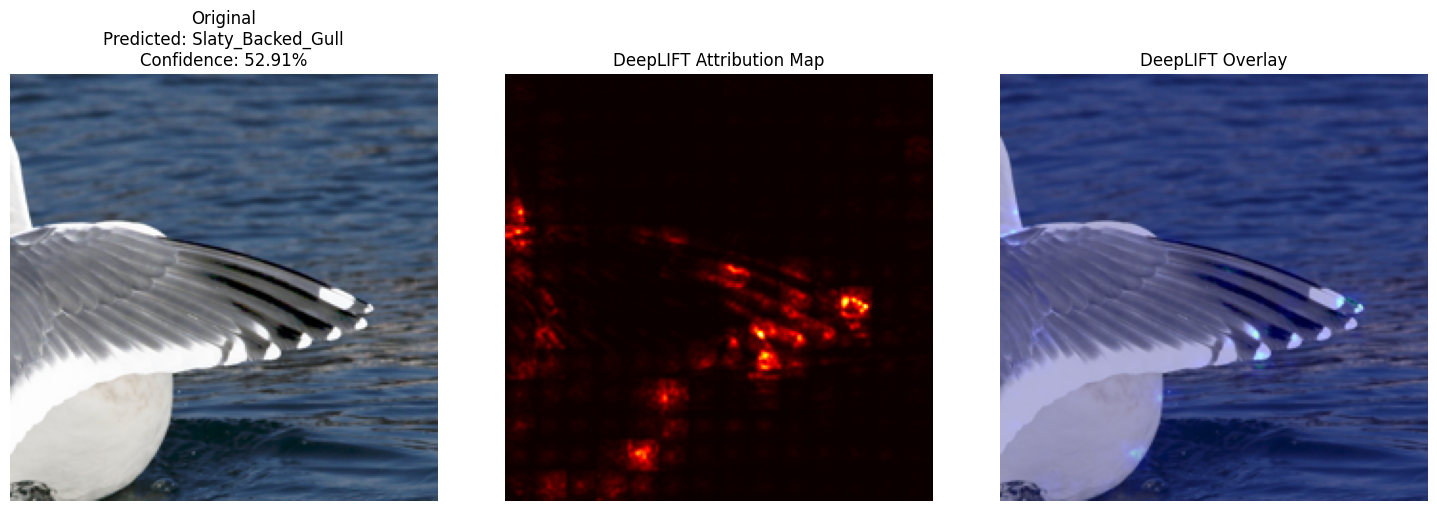

In [ ]:

import torch
import torch.nn as nn
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import timm
import os
from typing import Tuple, Optional
from torchvision import transforms
from captum.attr import DeepLift

class ViTModified(nn.Module):
    def __init__(self, num_classes: int = 2, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=pretrained)
        num_ftrs = self.vit.head.in_features
        self.vit.head = nn.Linear(num_ftrs, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.vit(x)

class DeepLIFTAnalyzer:
    def __init__(self, model: nn.Module, class_names: list, device: str = 'cuda' if torch.cuda.is_available() else 'cpu'):
        self.model = model.to(device)
        self.device = device
        self.class_names = class_names
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])
        self.deep_lift = DeepLift(self.model)

    def preprocess_image(self, image_path: str) -> Tuple[torch.Tensor, np.ndarray]:
        """Preprocess image and return both tensor and original image."""
        original_image = Image.open(image_path).convert("RGB")
        original_image = original_image.resize((224, 224))
        original_np = np.array(original_image)

        image_tensor = self.transform(original_image).unsqueeze(0).to(self.device)
        return image_tensor, original_np

    def generate_deeplift_attribution(self, image_tensor: torch.Tensor) -> Tuple[np.ndarray, int, float]:
        """Generate DeepLIFT attribution map with confidence score."""
        self.model.eval()

        # Create baseline (zero tensor)
        baseline = torch.zeros_like(image_tensor).to(self.device)

        # Get prediction and confidence
        with torch.no_grad():
            output = self.model(image_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            confidence_score = torch.max(probabilities).item()
            pred_class = output.argmax().item()

        # Generate attribution
        try:
            attribution = self.deep_lift.attribute(
                image_tensor,
                baselines=baseline,
                target=pred_class,
                return_convergence_delta=False
            )

            # Properly detach and convert to numpy
            attribution = attribution.detach().cpu().numpy()

            # Process the attribution map for visualization
            attribution = np.mean(np.abs(attribution), axis=1)  # Average across channels
            attribution = attribution.squeeze()

            # Resize attribution map to match image size (14x14 -> 224x224)
            attribution = cv2.resize(attribution, (224, 224))

            # Normalize attribution map
            attribution = (attribution - attribution.min()) / (attribution.max() - attribution.min() + 1e-8)

            # Apply Gaussian blur for smoothing
            attribution = cv2.GaussianBlur(attribution, (3, 3), 0)

        except Exception as e:
            print(f"Error generating attribution: {str(e)}")
            # Return a uniform attribution map in case of error
            attribution = np.ones((224, 224)) * 0.5

        return attribution, pred_class, confidence_score

    def create_overlay(self, original_image: np.ndarray, attribution: np.ndarray,
                      alpha: float = 0.7, colormap: int = cv2.COLORMAP_JET) -> np.ndarray:
        """Create colored overlay of attribution map on original image."""
        attribution_map = np.uint8(attribution * 255)
        heatmap = cv2.applyColorMap(attribution_map, colormap)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

        overlay = cv2.addWeighted(original_image, alpha, heatmap, 1 - alpha, 0)
        return overlay

    def visualize_attribution(self, image_path: str,
                            save_path: Optional[str] = None,
                            figure_size: Tuple[int, int] = (15, 5)):
        """Visualize original image, DeepLIFT attribution, and overlay."""
        # Process image
        image_tensor, original_image = self.preprocess_image(image_path)
        attribution, pred_class, confidence = self.generate_deeplift_attribution(image_tensor)

        # Create overlay
        overlay_image = self.create_overlay(original_image, attribution)

        # Visualization
        fig, axes = plt.subplots(1, 3, figsize=figure_size)

        # Original image
        axes[0].imshow(original_image)
        axes[0].set_title(f"Original\nPredicted: {self.class_names[pred_class]}\nConfidence: {confidence:.2%}")
        axes[0].axis('off')

        # Attribution map
        axes[1].imshow(attribution, cmap='hot')
        axes[1].set_title('DeepLIFT Attribution Map')
        axes[1].axis('off')

        # Overlay
        axes[2].imshow(overlay_image)
        axes[2].set_title('DeepLIFT Overlay')
        axes[2].axis('off')

        plt.tight_layout()

        if save_path:
            plt.savefig(save_path, bbox_inches='tight', dpi=300)
            plt.close()
        else:
            plt.show()

def analyze_single_image(analyzer: DeepLIFTAnalyzer, image_path: str):
    """Process a single image."""
    if os.path.exists(image_path):
        print(f"Processing: {image_path}")
        analyzer.visualize_attribution(image_path)
    else:
        print(f"Image not found: {image_path}")

if __name__ == "__main__":
    # Initialize model and analyzer
    model = ViTModified()
    model.load_state_dict(torch.load('/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model_vit_20241224.pth',
                                   map_location='cpu'))
    class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

    analyzer = DeepLIFTAnalyzer(model, class_names)

    # Get the path of the uploaded image
    image_path = '/content/sbgfake.png'

    # Analyze the single image
    analyze_single_image(analyzer, image_path)

In [ ]:
!pip install captum
import torch
import torch.nn as nn
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import timm
import os
from typing import Tuple, Optional
from torchvision import transforms
from captum.attr import DeepLift

class ViTModified(nn.Module):
    def __init__(self, num_classes: int = 2, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=pretrained)
        num_ftrs = self.vit.head.in_features
        self.vit.head = nn.Linear(num_ftrs, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.vit(x)

class DeepLIFTAnalyzer:
    def __init__(self, model: nn.Module, class_names: list, device: str = 'cuda' if torch.cuda.is_available() else 'cpu'):
        self.model = model.to(device)
        self.device = device
        self.class_names = class_names
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])
        self.deep_lift = DeepLift(self.model)

    def preprocess_image(self, image_path: str) -> Tuple[torch.Tensor, np.ndarray]:
        """Preprocess image and return both tensor and original image."""
        original_image = Image.open(image_path).convert("RGB")
        original_image = original_image.resize((224, 224))
        original_np = np.array(original_image)

        image_tensor = self.transform(original_image).unsqueeze(0).to(self.device)
        return image_tensor, original_np

    def generate_deeplift_attribution(self, image_tensor: torch.Tensor) -> Tuple[np.ndarray, int, float]:
        """Generate DeepLIFT attribution map with confidence score."""
        self.model.eval()

        # Create baseline (zero tensor)
        baseline = torch.zeros_like(image_tensor).to(self.device)

        # Get prediction and confidence
        with torch.no_grad():
            output = self.model(image_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            confidence_score = torch.max(probabilities).item()
            pred_class = output.argmax().item()

        # Generate attribution
        try:
            attribution = self.deep_lift.attribute(
                image_tensor,
                baselines=baseline,
                target=pred_class,
                return_convergence_delta=False
            )

            # Properly detach and convert to numpy
            attribution = attribution.detach().cpu().numpy()

            # Process the attribution map for visualization
            attribution = np.mean(np.abs(attribution), axis=1)  # Average across channels
            attribution = attribution.squeeze()

            # Resize attribution map to match image size (14x14 -> 224x224)
            attribution = cv2.resize(attribution, (224, 224))

            # Normalize attribution map
            attribution = (attribution - attribution.min()) / (attribution.max() - attribution.min() + 1e-8)

            # Apply Gaussian blur for smoothing
            attribution = cv2.GaussianBlur(attribution, (3, 3), 0)

        except Exception as e:
            print(f"Error generating attribution: {str(e)}")
            # Return a uniform attribution map in case of error
            attribution = np.ones((224, 224)) * 0.5

        return attribution, pred_class, confidence_score

    def create_overlay(self, original_image: np.ndarray, attribution: np.ndarray,
                      alpha: float = 0.7, colormap: int = cv2.COLORMAP_JET) -> np.ndarray:
        """Create colored overlay of attribution map on original image."""
        attribution_map = np.uint8(attribution * 255)
        heatmap = cv2.applyColorMap(attribution_map, colormap)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

        overlay = cv2.addWeighted(original_image, alpha, heatmap, 1 - alpha, 0)
        return overlay

    def visualize_attribution(self, image_path: str,
                            save_path: Optional[str] = None,
                            figure_size: Tuple[int, int] = (15, 5)):
        """Visualize original image, DeepLIFT attribution, and overlay."""
        # Process image
        image_tensor, original_image = self.preprocess_image(image_path)
        attribution, pred_class, confidence = self.generate_deeplift_attribution(image_tensor)

        # Create overlay
        overlay_image = self.create_overlay(original_image, attribution)

        # Visualization
        fig, axes = plt.subplots(1, 3, figsize=figure_size)

        # Original image
        axes[0].imshow(original_image)
        axes[0].set_title(f"Original\nPredicted: {self.class_names[pred_class]}\nConfidence: {confidence:.2%}")
        axes[0].axis('off')

        # Attribution map
        axes[1].imshow(attribution, cmap='hot')
        axes[1].set_title('DeepLIFT Attribution Map')
        axes[1].axis('off')

        # Overlay
        axes[2].imshow(overlay_image)
        axes[2].set_title('DeepLIFT Overlay')
        axes[2].axis('off')

        plt.tight_layout()

        if save_path:
            plt.savefig(save_path, bbox_inches='tight', dpi=300)
            plt.close()
        else:
            plt.show()

def analyze_dataset(analyzer: DeepLIFTAnalyzer, test_folder: str):
    """Process all images in a test folder."""
    for root, _, files in os.walk(test_folder):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                image_path = os.path.join(root, file)
                print(f"Processing: {image_path}")
                analyzer.visualize_attribution(image_path)

if __name__ == "__main__":
    # Initialize model and analyzer
    model = ViTModified()
    model.load_state_dict(torch.load('/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model_vit_20241224.pth',
                                   map_location='cpu'))
    class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

    analyzer = DeepLIFTAnalyzer(model, class_names)

    # Analyze test dataset
    test_folder = '/content/drive/My Drive/FYP/refinetest'
    analyze_dataset(analyzer, test_folder)

Output hidden; open in https://colab.research.google.com to view.